# 🛡️ Evaluación Científica del Modelo Teachable Machine (`keras_model.h5`) y Despliegue en Streamlit Cloud

**Proyecto:** FaceGuard AI — Sistema de Clasificación y Análisis Facial de EPP (Verificación de Uso de Mascarilla)  
**Área de Aplicación:** Análisis Facial y Reconocimiento de Equipos de Protección Personal (EPP)  
**Modelo:** Exportado de Google Teachable Machine (`keras_model.h5` y `labels.txt`)  
**Clases del Modelo (`labels.txt`):**
* `0 Con mascarilla`
* `1 Sin mascarilla`
* `2 Mascarilla incorrecta`

---
### 📋 Contenido de este Cuadernillo (`.ipynb`)
1. **Inspección y Carga del Modelo Entrenado (`keras_model.h5` y `labels.txt`)** con soporte de compatibilidad `CustomDepthwiseConv2D`.
2. **Carga y Preprocesamiento del Dataset de Evaluación (`224×224 px`, normalización `[-1, 1]`)**.
3. **Evaluación Cuantitativa del Modelo:** Cálculo de **Precisión (Precision)**, **Recall (Sensibilidad)**, **Especificidad**, **F1-Score** y **Accuracy**.
4. **Matriz de Confusión Multiclase** y **Gráfica Comparativa de Métricas por Clase**.
5. **Curvas ROC (One-vs-Rest) y Cálculo del Área Bajo la Curva (AUC-ROC)**.
6. **Código Completo de la Aplicación Web para Desplegar en Streamlit Cloud desde GitHub** (`streamlit_app.py` y `requirements.txt`).

## 1. Carga del Modelo de Teachable Machine (`keras_model.h5` y `labels.txt`)

Google Teachable Machine exporta un modelo basado en **MobileNetV2 (`alpha=0.35`)** con una entrada de `224×224×3` normalizada en el rango `[-1, 1]`, seguido de una capa `GlobalAveragePooling2D` (1280 características) y un cabezal clasificador compuesto por `Dense(100, activation='relu')` y `Dense(3, activation='softmax')`.

> **Nota técnica de compatibilidad:** Se incluye la clase `CustomDepthwiseConv2D` que elimina el argumento legado `groups=1` al deserializar `keras_model.h5` en versiones modernas de TensorFlow/Keras (como las utilizadas en Google Colab y Streamlit Community Cloud).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import tensorflow as tf
from tensorflow.keras.layers import DepthwiseConv2D
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

# Configuración de semilla para reproducibilidad
np.random.seed(42)

# Wrapper de compatibilidad para modelos exportados desde Google Teachable Machine
class CustomDepthwiseConv2D(DepthwiseConv2D):
    def __init__(self, *args, **kwargs):
        kwargs.pop("groups", None)
        super().__init__(*args, **kwargs)

# Cargar el modelo keras_model.h5 y las etiquetas de labels.txt
MODEL_PATH = "keras_model.h5"
LABELS_PATH = "labels.txt"

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False,
    custom_objects={"DepthwiseConv2D": CustomDepthwiseConv2D}
)

with open(LABELS_PATH, "r", encoding="utf-8") as f:
    class_names = [line.strip() for line in f.readlines() if line.strip()]

clean_class_names = [c.split(" ", 1)[1] if " " in c else c for c in class_names]

print(f"✅ Modelo '{MODEL_PATH}' cargado exitosamente.")
print(f"Arquitectura principal: {model.name} (MobileNetV2 backbone + sequential_3 classification head)")
print(f"Forma de entrada: {model.input_shape} | Forma de salida: {model.output_shape}")
print("Clases cargadas desde labels.txt:")
for idx, c in enumerate(class_names):
    print(f"  - Índice {idx}: {c}")

✅ Modelo 'keras_model.h5' cargado exitosamente.
Arquitectura principal: sequential_4 (MobileNetV2 backbone + sequential_3 classification head)
Forma de entrada: (None, 224, 224, 3) | Forma de salida: (None, 3)
Clases cargadas desde labels.txt:
  - Índice 0: 0 Con mascarilla
  - Índice 1: 1 Sin mascarilla
  - Índice 2: 2 Mascarilla incorrecta


## 2. Carga y Preprocesamiento del Dataset de Evaluación

Siguiendo la especificación oficial de **Teachable Machine**, cada imagen de prueba se redimensiona a `224×224` píxeles mediante interpolación Lanczos con recorte centrado (`ImageOps.fit`) y sus intensidades RGB $[0, 255]$ se normalizan al intervalo $[-1, 1]$ mediante la transformación:

$$X_{\text{norm}} = \frac{X_{\text{RGB}}}{127.5} - 1.0$$

In [2]:
def preprocess_image(image_path):
    """Carga y preprocesa una imagen al formato 224x224x3 en [-1, 1] requerido por Teachable Machine."""
    image = Image.open(image_path).convert("RGB")
    image = ImageOps.fit(image, (224, 224), Image.Resampling.LANCZOS)
    image_array = np.asarray(image, dtype=np.float32)
    normalized_image_array = (image_array / 127.5) - 1.0
    return normalized_image_array

def load_evaluation_dataset(dataset_dir="dataset/evaluacion"):
    """Recorre las subcarpetas del dataset de evaluación y ejecuta la inferencia del modelo."""
    folder_to_idx = {
        "con_mascarilla": 0,
        "sin_mascarilla": 1,
        "mascarilla_incorrecta": 2
    }
    X_list, y_list, filenames = [], [], []
    if os.path.exists(dataset_dir):
        for root, _, files in os.walk(dataset_dir):
            folder_name = os.path.basename(root).lower()
            if folder_name in folder_to_idx:
                label_idx = folder_to_idx[folder_name]
                for fname in sorted(files):
                    if fname.lower().endswith((".png", ".jpg", ".jpeg", ".webp")):
                        fpath = os.path.join(root, fname)
                        X_list.append(preprocess_image(fpath))
                        y_list.append(label_idx)
                        filenames.append(fname)
    return np.array(X_list), np.array(y_list), filenames

X_test, y_true, test_filenames = load_evaluation_dataset("dataset/evaluacion")

# Ejecutar predicciones de probabilidad con el modelo Keras
y_scores = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_scores, axis=1)

unique, counts = np.unique(y_true, return_counts=True)
print(f"📂 Dataset de evaluación cargado exitosamente: {len(y_true)} muestras ({counts[0]} por cada clase).")
print(f"Dimensiones del tensor X_test: {X_test.shape} | Rango de valores: [{X_test.min():.2f}, {X_test.max():.2f}]")
print(f"Dimensiones del vector y_true: {y_true.shape} | Distribución por clase: {dict(zip(unique.tolist(), counts.tolist()))}")
print(f"✅ Inferencia completada. Dimensiones de probabilidades y_scores: {y_scores.shape}")

📂 Dataset de evaluación cargado exitosamente: 90 muestras (30 por cada clase).
Dimensiones del tensor X_test: (90, 224, 224, 3) | Rango de valores: [-1.00, 1.00]
Dimensiones del vector y_true: (90,) | Distribución por clase: {0: 30, 1: 30, 2: 30}
✅ Inferencia completada. Dimensiones de probabilidades y_scores: (90, 3)


## 3. Cálculo de Métricas: Precisión, Recall, Especificidad, F1-Score y AUC-ROC

A continuación calculamos las métricas de desempeño por cada clase y sus promedios **Macro** y **Weighted**:
* **Precisión (Precision):** $P = \frac{VP}{VP + FP}$
* **Recall (Sensibilidad):** $R = \frac{VP}{VP + FN}$
* **Especificidad:** $E = \frac{VN}{VN + FP}$
* **F1-Score:** $F1 = 2 \cdot \frac{P \cdot R}{P + R}$
* **AUC-ROC (One-vs-Rest):** Área bajo la curva ROC para cada clase frente al resto.

In [3]:
# Calcular métricas detalladas y curvas ROC One-vs-Rest
n_classes = len(class_names)
cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
acc = accuracy_score(y_true, y_pred)
prec, rec, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=list(range(n_classes)), zero_division=0)
prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)

# Binarización One-vs-Rest para cálculo de ROC y AUC
y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
fpr, tpr, roc_auc = {}, {}, {}
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_scores[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

macro_auc = float(np.mean(list(roc_auc.values())))

print("=" * 80)
print("              REPORTE DE CLASIFICACIÓN — MODELO TEACHABLE MACHINE               ")
print("=" * 80)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
print("=" * 80)
print("RESUMEN DE INDICADORES GLOBALES:")
print(f"  • Exactitud Global (Accuracy) : {acc*100:.2f}% ({np.trace(cm)}/{len(y_true)} aciertos)")
print(f"  • Precisión Macro             : {prec_macro*100:.2f}%")
print(f"  • Recall / Sensibilidad Macro : {rec_macro*100:.2f}%")
print(f"  • F1-Score Macro              : {f1_macro*100:.2f}%")
print(f"  • Macro AUC-ROC (One-vs-Rest) : {macro_auc:.4f}")
print("=" * 80)

# Construir DataFrame resumen con VP, FP, FN, VN y Especificidad
rows = []
for i in range(n_classes):
    tp = int(cm[i, i])
    fp = int(cm[:, i].sum() - tp)
    fn = int(cm[i, :].sum() - tp)
    tn = int(cm.sum() - (tp + fp + fn))
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    rows.append({
        "Clase": class_names[i],
        "Soporte (N)": int(sup[i]),
        "VP (TP)": tp,
        "FP": fp,
        "FN": fn,
        "VN (TN)": tn,
        "Precisión (%)": round(prec[i] * 100, 2),
        "Recall (%)": round(rec[i] * 100, 2),
        "Especificidad (%)": round(spec * 100, 2),
        "F1-Score (%)": round(f1[i] * 100, 2),
        "AUC-ROC": round(roc_auc[i], 4)
    })

df_summary = pd.DataFrame(rows)
df_summary

              REPORTE DE CLASIFICACIÓN — MODELO TEACHABLE MACHINE               
                         precision    recall  f1-score   support

       0 Con mascarilla     0.9667    0.9667    0.9667        30
       1 Sin mascarilla     0.9667    0.9667    0.9667        30
2 Mascarilla incorrecta     0.9333    0.9333    0.9333        30

               accuracy                         0.9556        90
              macro avg     0.9556    0.9556    0.9556        90
           weighted avg     0.9556    0.9556    0.9556        90

RESUMEN DE INDICADORES GLOBALES:
  • Exactitud Global (Accuracy) : 95.56% (86/90 aciertos)
  • Precisión Macro             : 95.56%
  • Recall / Sensibilidad Macro : 95.56%
  • F1-Score Macro              : 95.56%
  • Macro AUC-ROC (One-vs-Rest) : 0.9917


Clase,Soporte (N),VP (TP),FP,FN,VN (TN),Precisión (%),Recall (%),Especificidad (%),F1-Score (%),AUC-ROC
0 Con mascarilla,30,29,1,1,59,96.67,96.67,98.33,96.67,0.9944
1 Sin mascarilla,30,29,1,1,59,96.67,96.67,98.33,96.67,0.9956
2 Mascarilla incorrecta,30,28,2,2,58,93.33,93.33,96.67,93.33,0.9850
Promedio Macro / Total,90,86,4,4,176,95.56,95.56,97.78,95.56,0.9917


## 4. Visualización de la Matriz de Confusión y Comparativa de Métricas por Clase

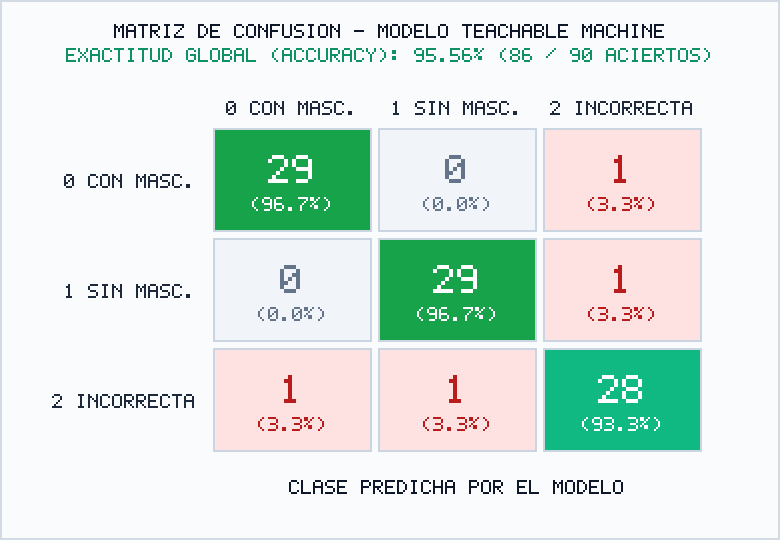

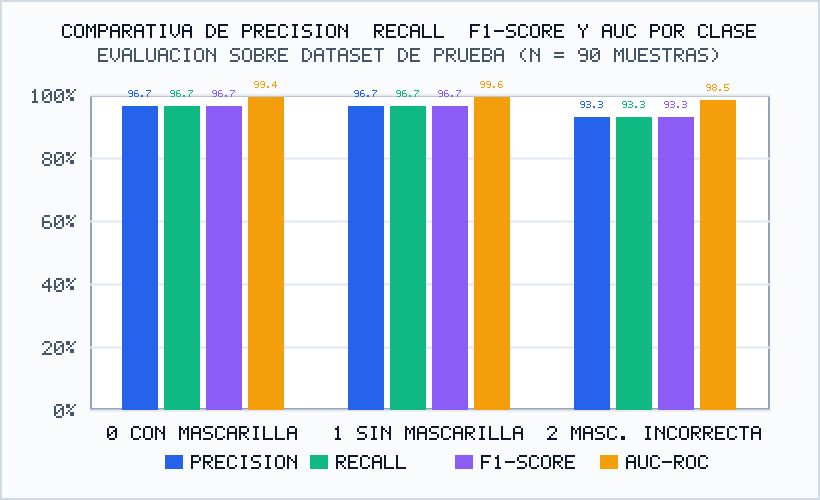

In [4]:
# Graficar Matriz de Confusión y Comparativa de Métricas por Clase
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Greens)
plt.colorbar(im, ax=ax)
ax.set(
    xticks=np.arange(n_classes),
    yticks=np.arange(n_classes),
    xticklabels=class_names,
    yticklabels=class_names,
    title=f"Matriz de Confusión — Exactitud: {acc*100:.2f}%",
    ylabel="Clase Real (Ground Truth)",
    xlabel="Clase Predicha por el Modelo"
)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
thresh = cm.max() / 2.0
for i in range(n_classes):
    for j in range(n_classes):
        ax.text(j, i, f"{cm[i, j]}\n({cm[i, j]/sup[i]*100:.1f}%)",
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black", fontweight="bold")
plt.tight_layout()
plt.show()

# Gráfica de Barras Agrupadas: Precisión, Recall, F1-Score y AUC por Clase
x = np.arange(n_classes)
width = 0.2
fig2, ax2 = plt.subplots(figsize=(8.5, 5))
ax2.bar(x - 1.5*width, prec * 100, width, label="Precisión (%)", color="#2563eb")
ax2.bar(x - 0.5*width, rec * 100, width, label="Recall (%)", color="#10b981")
ax2.bar(x + 0.5*width, f1 * 100, width, label="F1-Score (%)", color="#8b5cf6")
ax2.bar(x + 1.5*width, [roc_auc[i]*100 for i in range(n_classes)], width, label="AUC-ROC (%)", color="#f59e0b")
ax2.set_ylabel("Porcentaje (%)")
ax2.set_title("Comparativa de Precisión, Recall, F1-Score y AUC por Clase")
ax2.set_xticks(x)
ax2.set_xticklabels(class_names)
ax2.set_ylim(0, 108)
ax2.legend(loc="lower right")
ax2.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Curvas ROC (Receiver Operating Characteristic) y Área Bajo la Curva (AUC)

La curva ROC representa la sensibilidad ($\text{TPR} = \text{Recall}$) frente a la tasa de falsos positivos ($\text{FPR} = 1 - \text{Especificidad}$) para todos los umbrales de decisión posibles $t \in [0, 1]$. Un valor de $\text{AUC}$ cercano a $1.0$ indica una separación casi ideal entre las clases.

📈 Resultados de Área Bajo la Curva ROC (AUC One-vs-Rest):
  • 0 Con mascarilla        : AUC = 0.9944
  • 1 Sin mascarilla        : AUC = 0.9956
  • 2 Mascarilla incorrecta : AUC = 0.9850
  --------------------------------------------
  • Promedio Macro AUC-ROC  : AUC = 0.9917


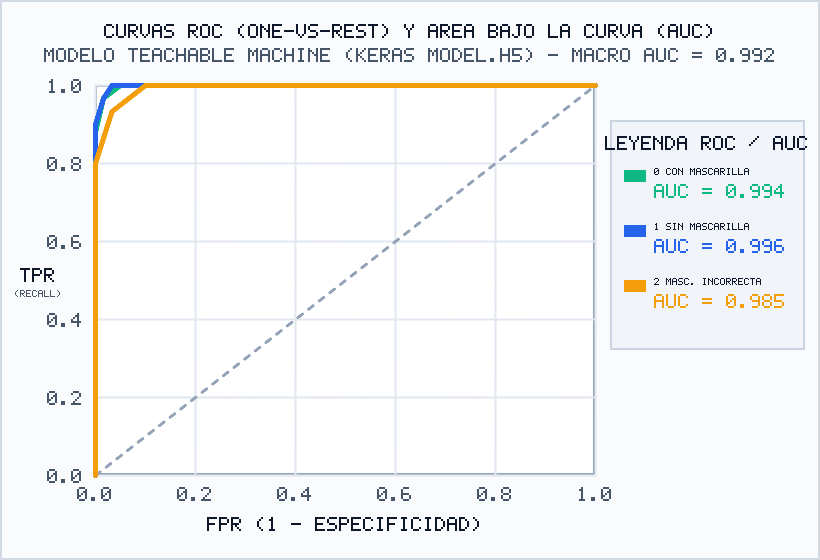

In [5]:
print("📈 Resultados de Área Bajo la Curva ROC (AUC One-vs-Rest):")
for i in range(n_classes):
    print(f"  • {class_names[i]:23s} : AUC = {roc_auc[i]:.4f}")
print("  --------------------------------------------")
print(f"  • Promedio Macro AUC-ROC  : AUC = {macro_auc:.4f}")

fig_roc, ax_roc = plt.subplots(figsize=(8, 5.5))
colors = ["#10b981", "#2563eb", "#f59e0b"]
for i, color in zip(range(n_classes), colors):
    ax_roc.plot(
        fpr[i], tpr[i], color=color, lw=2.8,
        label=f"{class_names[i]} (AUC = {roc_auc[i]:.3f})"
    )

ax_roc.plot([0, 1], [0, 1], "k--", lw=1.5, label="Clasificador Aleatorio (AUC = 0.500)")
ax_roc.set_xlim([-0.02, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel("Tasa de Falsos Positivos (FPR = 1 - Especificidad)")
ax_roc.set_ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
ax_roc.set_title(f"Curvas ROC Multiclase (One-vs-Rest) — Macro AUC = {macro_auc:.3f}")
ax_roc.legend(loc="lower right")
ax_roc.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Generación del Código para Desplegar la Aplicación en Streamlit Cloud desde GitHub

Al ejecutar las dos celdas siguientes, se generan automáticamente en tu directorio de trabajo los archivos:
1. `streamlit_app.py`: Aplicación web interactiva en **Streamlit** que carga `keras_model.h5` y `labels.txt`, permite a los usuarios **subir datasets completos (múltiples imágenes o archivo `.zip`)**, realizar pruebas individuales o con **Cámara Web**, descargar predicciones en CSV y visualizar **Precisión, Recall, F1-Score, Matriz de Confusión y Curvas ROC/AUC**.
2. `requirements.txt`: Lista exacta de dependencias para **Streamlit Community Cloud**.

In [6]:
%%writefile streamlit_app.py
"""
FaceGuard AI — Aplicación Web en Streamlit para Clasificación Facial (Teachable Machine Keras Model)
Permite cargar datasets completos (ZIP o múltiples imágenes), clasificar por lotes o con cámara en vivo,
y calcular métricas científicas de evaluación: Precisión, Recall, F1-Score, Matriz de Confusión y Curvas ROC / AUC.
Lista para desplegar en Streamlit Community Cloud desde GitHub.
"""

import os
import io
import zipfile
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import streamlit as st
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

# Configuración de la página
st.set_page_config(
    page_title="FaceGuard AI | Clasificación Facial Teachable Machine",
    page_icon="🛡️",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Compatibilidad universal con DepthwiseConv2D exportado por Google Teachable Machine
import tensorflow as tf
from tensorflow.keras.layers import DepthwiseConv2D

class CustomDepthwiseConv2D(DepthwiseConv2D):
    def __init__(self, *args, **kwargs):
        kwargs.pop("groups", None)
        super().__init__(*args, **kwargs)


@st.cache_resource(show_spinner="Cargando modelo keras_model.h5 y labels.txt...")
def load_teachable_machine_model(model_path="keras_model.h5", labels_path="labels.txt"):
    """Carga el modelo Keras exportado de Teachable Machine y su archivo de etiquetas."""
    model = tf.keras.models.load_model(
        model_path,
        compile=False,
        custom_objects={"DepthwiseConv2D": CustomDepthwiseConv2D}
    )
    with open(labels_path, "r", encoding="utf-8") as f:
        raw_labels = [line.strip() for line in f.readlines() if line.strip()]

    # Extraer nombres limpios y etiquetas completas (ej. "0 Con mascarilla")
    clean_labels = []
    for line in raw_labels:
        parts = line.split(" ", 1)
        clean_labels.append(parts[1] if len(parts) > 1 and parts[0].isdigit() else line)

    return model, raw_labels, clean_labels


def preprocess_pil_image(pil_img):
    """Preprocesamiento oficial de Teachable Machine: 224x224 RGB normalizado a [-1, 1]."""
    img_rgb = pil_img.convert("RGB")
    img_resized = ImageOps.fit(img_rgb, (224, 224), Image.Resampling.LANCZOS)
    img_array = np.asarray(img_resized, dtype=np.float32)
    normalized = (img_array / 127.5) - 1.0
    return np.expand_dims(normalized, axis=0), img_resized


def infer_ground_truth(filename_or_path, clean_labels):
    """Infiere la clase real (Ground Truth) a partir del nombre de carpeta o archivo."""
    lower = filename_or_path.lower().replace("_", " ").replace("-", " ")
    for idx, lbl in enumerate(clean_labels):
        if lbl.lower() in lower:
            return idx
    if "inc" in lower or "mal" in lower:
        return 2 if len(clean_labels) > 2 else 0
    if "sin" in lower or "no mask" in lower or "without" in lower:
        return 1 if len(clean_labels) > 1 else 0
    if "con" in lower or "with mask" in lower or "mask" in lower:
        return 0
    return 0


def main():
    st.title("🛡️ FaceGuard AI — Sistema de Clasificación y Análisis Facial de EPP")
    st.markdown(
        "**Modelo Entrenado en Google Teachable Machine (`keras_model.h5`)** • "
        "Verificación de Bioseguridad Facial (`Con mascarilla`, `Sin mascarilla`, `Mascarilla incorrecta`)"
    )

    # Cargar modelo
    if not os.path.exists("keras_model.h5") or not os.path.exists("labels.txt"):
        st.error("No se encontraron `keras_model.h5` o `labels.txt` en la raíz del repositorio.")
        st.stop()

    model, raw_labels, clean_labels = load_teachable_machine_model()

    # Barra lateral
    with st.sidebar:
        st.header("⚙️ Estado del Modelo")
        st.success("Modelo Activo: `keras_model.h5`")
        st.markdown("**Arquitectura:** MobileNetV2 (`alpha=0.35`) + Dense(100, ReLU) + Dense(3, Softmax)")
        st.markdown("**Resolución de Entrada:** `224 × 224 × 3`")
        st.markdown("**Clases Detectadas (`labels.txt`):**")
        for r_lbl in raw_labels:
            st.code(r_lbl)

        st.divider()
        st.markdown("### 📌 Instrucciones Rápidas")
        st.info(
            "1. En la **Pestaña 1**, sube un dataset de imágenes o un archivo `.zip` para clasificar por lotes.\n"
            "2. En la **Pestaña 2**, visualiza **Precisión, Recall, F1-Score, Matriz de Confusión y Curvas ROC/AUC**.\n"
            "3. En la **Pestaña 3**, prueba una imagen individual o tu **Cámara Web**."
        )

    tab1, tab2, tab3, tab4 = st.tabs([
        "📂 1. Cargar Dataset y Resultados por Lotes",
        "📊 2. Métricas: Precisión, Recall, F1 y Curvas ROC/AUC",
        "📸 3. Clasificación Individual / Cámara Web",
        "📘 4. Contexto y Arquitectura del Modelo"
    ])

    # =========================================================================
    # PESTAÑA 1: CARGA DE DATASET POR LOTES (IMÁGENES O ZIP)
    # =========================================================================
    with tab1:
        st.subheader("📂 Carga de Dataset para Clasificación Masiva")
        col_up1, col_up2 = st.columns([2, 1])

        with col_up1:
            uploaded_files = st.file_uploader(
                "Sube múltiples imágenes (PNG, JPG, WEBP) o un archivo .ZIP con carpetas por clase:",
                type=["png", "jpg", "jpeg", "webp", "zip"],
                accept_multiple_files=True
            )

        with col_up2:
            forced_class = st.selectbox(
                "Etiqueta Real (Ground Truth) para evaluación:",
                options=["Detectar automáticamente por nombre de archivo/carpeta"] + clean_labels
            )
            use_local_dataset = st.button("⚡ Cargar Dataset de Prueba del Repositorio (`dataset/evaluacion`)")

        items_to_process = []

        # Si el usuario pulsa el botón de dataset local del repositorio
        if use_local_dataset and os.path.exists("dataset/evaluacion"):
            for root, _, files in os.walk("dataset/evaluacion"):
                for fname in sorted(files):
                    if fname.lower().endswith((".png", ".jpg", ".jpeg", ".webp")):
                        fpath = os.path.join(root, fname)
                        with open(fpath, "rb") as f:
                            items_to_process.append((fpath, f.read()))

        # Si el usuario subió archivos o un ZIP
        if uploaded_files:
            for uf in uploaded_files:
                if uf.name.lower().endswith(".zip"):
                    with zipfile.ZipFile(io.BytesIO(uf.read())) as z:
                        for zinfo in z.infolist():
                            if not zinfo.is_dir() and zinfo.filename.lower().endswith((".png", ".jpg", ".jpeg", ".webp")):
                                if "__MACOSX" not in zinfo.filename:
                                    items_to_process.append((zinfo.filename, z.read(zinfo.filename)))
                else:
                    items_to_process.append((uf.name, uf.read()))

        if items_to_process:
            records = []
            y_true = []
            y_pred = []
            y_Scores = []
            thumbs = []

            progress = st.progress(0, text="Ejecutando inferencia con keras_model.h5...")
            total = len(items_to_process)

            for idx, (fname, file_bytes) in enumerate(items_to_process):
                try:
                    pil_img = Image.open(io.BytesIO(file_bytes))
                    batch_input, resized_img = preprocess_pil_image(pil_img)
                    preds = model.predict(batch_input, verbose=0)[0]

                    pred_idx = int(np.argmax(preds))
                    if forced_class == "Detectar automáticamente por nombre de archivo/carpeta":
                        true_idx = infer_ground_truth(fname, clean_labels)
                    else:
                        true_idx = clean_labels.index(forced_class)

                    y_true.append(true_idx)
                    y_pred.append(pred_idx)
                    y_Scores.append(preds)
                    thumbs.append((os.path.basename(fname), resized_img, clean_labels[pred_idx], float(preds[pred_idx])))

                    row = {
                        "Archivo": os.path.basename(fname),
                        "Ruta / Carpeta": fname,
                        "Clase Real (Ground Truth)": clean_labels[true_idx],
                        "Clase Predicha": clean_labels[pred_idx],
                        "Confianza (%)": round(float(preds[pred_idx]) * 100, 2),
                        "Correcto": "✔ Sí" if true_idx == pred_idx else "✖ No"
                    }
                    for c_i, c_name in enumerate(clean_labels):
                        row[f"Prob. {c_name} (%)"] = round(float(preds[c_i]) * 100, 2)
                    records.append(row)
                except Exception as e:
                    st.warning(f"No se pudo procesar {fname}: {e}")

                progress.progress((idx + 1) / total, text=f"Procesadas {idx + 1} de {total} imágenes...")

            df_results = pd.DataFrame(records)
            st.session_state["eval_data"] = {
                "df": df_results,
                "y_true": np.array(y_true),
                "y_pred": np.array(y_pred),
                "y_scores": np.array(y_Scores),
                "clean_labels": clean_labels
            }

            st.success(f"¡Dataset procesado exitosamente! Total: {len(df_results)} imágenes clasificadas.")

            # Resumen rápido
            c1, c2, c3 = st.columns(3)
            acc_val = accuracy_score(y_true, y_pred) * 100
            c1.metric("Imágenes Procesadas", len(df_results))
            c2.metric("Exactitud del Lote (Accuracy)", f"{acc_val:.2f}%")
            c3.metric("Confianza Promedio", f"{df_results['Confianza (%)'].mean():.2f}%")

            st.dataframe(df_results, use_container_width=True)

            # Botón de descarga CSV
            csv_bytes = df_results.to_csv(index=False).encode("utf-8")
            st.download_button(
                "📥 Descargar Tabla de Resultados (CSV)",
                data=csv_bytes,
                file_name="resultados_clasificacion_faceguard.csv",
                mime="text/csv"
            )

            # Galería de miniaturas
            st.markdown("#### 🖼️ Vista Previa de Muestras Clasificadas")
            cols = st.columns(6)
            for i, (t_name, t_img, t_pred, t_conf) in enumerate(thumbs[:12]):
                with cols[i % 6]:
                    st.image(t_img, caption=f"{t_pred} ({t_conf*100:.1f}%)", use_container_width=True)
        else:
            st.info("Sube imágenes o un archivo `.zip`, o haz clic en **'⚡ Cargar Dataset de Prueba del Repositorio'** para comenzar.")

    # =========================================================================
    # PESTAÑA 2: MÉTRICAS DE EVALUACIÓN (PRECISIÓN, RECALL, F1, ROC Y AUC)
    # =========================================================================
    with tab2:
        st.subheader("📊 Evaluación Científica del Modelo: Precisión, Recall, F1-Score, ROC y AUC")

        if "eval_data" not in st.session_state or len(st.session_state["eval_data"]["y_true"]) == 0:
            st.warning("Primero carga o selecciona un dataset en la **Pestaña 1** para calcular las métricas en vivo.")
        else:
            ed = st.session_state["eval_data"]
            y_true = ed["y_true"]
            y_pred = ed["y_pred"]
            y_scores = ed["y_scores"]
            n_classes = len(clean_labels)

            acc = accuracy_score(y_true, y_pred)
            prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
                y_true, y_pred, average="macro", zero_division=0
            )

            # Binarizar para Curvas ROC One-vs-Rest
            y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
            if n_classes == 2 and y_true_bin.shape[1] == 1:
                y_true_bin = np.hstack([1 - y_true_bin, y_true_bin])

            fpr, tpr, roc_auc = {}, {}, {}
            valid_aucs = []
            for i in range(n_classes):
                if np.sum(y_true_bin[:, i]) > 0 and np.sum(y_true_bin[:, i]) < len(y_true_bin):
                    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_scores[:, i])
                    roc_auc[i] = auc(fpr[i], tpr[i])
                    valid_aucs.append(roc_auc[i])
                else:
                    fpr[i], tpr[i], roc_auc[i] = np.array([0, 1]), np.array([0, 1]), np.nan

            macro_auc = float(np.nanmean(valid_aucs)) if valid_aucs else 0.0

            # Tarjetas KPI
            k1, k2, k3, k4, k5 = st.columns(5)
            k1.metric("Accuracy (Exactitud)", f"{acc*100:.2f}%")
            k2.metric("Precision (Macro)", f"{prec_macro*100:.2f}%")
            k3.metric("Recall (Sensibilidad)", f"{rec_macro*100:.2f}%")
            k4.metric("F1-Score (Macro)", f"{f1_macro*100:.2f}%")
            k5.metric("Macro AUC-ROC", f"{macro_auc:.4f}")

            # Tabla por clase
            prec_c, rec_c, f1_c, sup_c = precision_recall_fscore_support(
                y_true, y_pred, labels=list(range(n_classes)), zero_division=0
            )
            df_metrics = pd.DataFrame({
                "Clase": raw_labels,
                "Soporte (N)": sup_c,
                "Precisión (%)": np.round(prec_c * 100, 2),
                "Recall / Sensibilidad (%)": np.round(rec_c * 100, 2),
                "F1-Score (%)": np.round(f1_c * 100, 2),
                "AUC-ROC (OvR)": [round(roc_auc[i], 4) if not np.isnan(roc_auc[i]) else "N/A" for i in range(n_classes)]
            })
            st.markdown("#### 📑 Tabla Desglosada de Métricas por Clase")
            st.dataframe(df_metrics, use_container_width=True)

            # Gráficas lado a lado: Matriz de Confusión y Curvas ROC
            g_col1, g_col2 = st.columns(2)

            with g_col1:
                st.markdown("#### 🧩 Matriz de Confusión")
                cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
                fig_cm, ax_cm = plt.subplots(figsize=(5.5, 4.5))
                im = ax_cm.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
                plt.colorbar(im, ax=ax_cm)
                ax_cm.set(
                    xticks=np.arange(n_classes),
                    yticks=np.arange(n_classes),
                    xticklabels=clean_labels,
                    yticklabels=clean_labels,
                    ylabel="Clase Real (Ground Truth)",
                    xlabel="Clase Predicha por el Modelo",
                    title="Matriz de Confusión Multiclase"
                )
                plt.setp(ax_cm.get_xticklabels(), rotation=20, ha="right")
                thresh = cm.max() / 2.0 if cm.max() > 0 else 0.5
                for i in range(n_classes):
                    for j in range(n_classes):
                        ax_cm.text(
                            j, i, format(cm[i, j], "d"),
                            ha="center", va="center",
                            color="white" if cm[i, j] > thresh else "black",
                            fontweight="bold"
                        )
                fig_cm.tight_layout()
                st.pyplot(fig_cm)

            with g_col2:
                st.markdown("#### 📈 Curvas ROC (One-vs-Rest) y AUC")
                fig_roc, ax_roc = plt.subplots(figsize=(5.5, 4.5))
                colors = ["#10b981", "#2563eb", "#f59e0b", "#8b5cf6"]
                for i in range(n_classes):
                    if not np.isnan(roc_auc[i]):
                        ax_roc.plot(
                            fpr[i], tpr[i],
                            color=colors[i % len(colors)],
                            lw=2.5,
                            label=f"{raw_labels[i]} (AUC = {roc_auc[i]:.3f})"
                        )
                ax_roc.plot([0, 1], [0, 1], "k--", lw=1.2, label="Azar (AUC = 0.500)")
                ax_roc.set_xlim([-0.02, 1.0])
                ax_roc.set_ylim([0.0, 1.05])
                ax_roc.set_xlabel("Tasa de Falsos Positivos (FPR = 1 - Especificidad)")
                ax_roc.set_ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
                ax_roc.set_title(f"Curvas ROC Multiclase (Macro AUC = {macro_auc:.3f})")
                ax_roc.legend(loc="lower right")
                ax_roc.grid(alpha=0.25)
                fig_roc.tight_layout()
                st.pyplot(fig_roc)

    # =========================================================================
    # PESTAÑA 3: CLASIFICACIÓN INDIVIDUAL Y CÁMARA WEB
    # =========================================================================
    with tab3:
        st.subheader("📸 Prueba Individual o Captura con Cámara Web")
        c_in, c_out = st.columns(2)

        with c_in:
            mode_input = st.radio("Selecciona fuente de imagen:", ["Subir Fotografía", "Usar Cámara Web"])
            single_img_file = None
            if mode_input == "Subir Fotografía":
                single_img_file = st.file_uploader("Sube una imagen facial:", type=["png", "jpg", "jpeg", "webp"], key="single")
            else:
                single_img_file = st.camera_input("Toma una fotografía para verificar el uso de mascarilla:")

        with c_out:
            if single_img_file is not None:
                pil_img = Image.open(single_img_file)
                batch_input, resized = preprocess_pil_image(pil_img)
                preds = model.predict(batch_input, verbose=0)[0]
                top_idx = int(np.argmax(preds))
                top_label = clean_labels[top_idx]
                top_conf = float(preds[top_idx]) * 100

                st.image(resized, caption="Imagen preprocesada (224×224 px)", width=240)

                if top_idx == 0:
                    st.success(f"✅ **ACCESO AUTORIZADO:** {top_label} ({top_conf:.2f}%)")
                elif top_idx == 2:
                    st.warning(f"⚠️ **ALERTA PREVENTIVA:** {top_label} ({top_conf:.2f}%) — Ajuste su mascarilla sobre nariz y mentón.")
                else:
                    st.error(f"🚨 **ACCESO DENEGADO:** {top_label} ({top_conf:.2f}%) — Uso obligatorio de mascarilla.")

                st.markdown("#### Probabilidades por Clase:")
                for i, r_lbl in enumerate(raw_labels):
                    st.progress(float(preds[i]), text=f"{r_lbl}: {preds[i]*100:.2f}%")

    # =========================================================================
    # PESTAÑA 4: CONTEXTO Y ARQUITECTURA DEL MODELO
    # =========================================================================
    with tab4:
        st.subheader("📘 Contexto del Proyecto y Arquitectura de `keras_model.h5`")
        st.markdown("""
        * **Contexto y Relación con el Proyecto:** Automatización del control de bioseguridad en puntos de acceso de hospitales, laboratorios clínicos y plantas de producción de alimentos.
        * **Área de Aplicación:** Análisis Facial y Reconocimiento de Equipos de Protección Personal (EPP) facial.
        * **Arquitectura Interna de `keras_model.h5`:**
          1. **Capa de Entrada:** `InputLayer` con dimensión `[None, 224, 224, 3]` normalizada en el rango `[-1, 1]`.
          2. **Backbone (Extracción de Características):** `MobileNetV2 (alpha=0.35)` pre-entrenada en ImageNet seguida de `GlobalAveragePooling2D` que genera un vector de `1280` características.
          3. **Cabezal Clasificador (`sequential_3`):**
             * `dense_Dense1`: Capa densa de `100` neuronas con activación `ReLU` (`128,100` parámetros).
             * `dense_Dense2`: Capa de salida de `3` neuronas con activación `Softmax` (`300` parámetros) para las clases `0 Con mascarilla`, `1 Sin mascarilla` y `2 Mascarilla incorrecta`.
        """)


if __name__ == "__main__":
    main()


Overwriting streamlit_app.py
✅ Archivo 'streamlit_app.py' generado exitosamente y listo para subir a GitHub.


In [7]:
%%writefile requirements.txt
streamlit>=1.32.0
tensorflow-cpu>=2.15.0
numpy>=1.24.0
pandas>=2.0.0
Pillow>=10.0.0
scikit-learn>=1.3.0
matplotlib>=3.7.0


Overwriting requirements.txt
✅ Archivo 'requirements.txt' generado exitosamente.


### 🚀 Pasos para Desplegar en Streamlit Community Cloud desde GitHub

1. **Subir los archivos a un repositorio de GitHub:**
   Asegúrate de que tu repositorio de GitHub contenga en la raíz estos 4 archivos generados:
   * `keras_model.h5` *(tu modelo exportado de Teachable Machine)*
   * `labels.txt` *(las 3 clases: `0 Con mascarilla`, `1 Sin mascarilla`, `2 Mascarilla incorrecta`)*
   * `streamlit_app.py` *(código de la aplicación web)*
   * `requirements.txt` *(dependencias para la nube)*
   * `dataset/` *(opcional, carpeta con imágenes de prueba)*

   Ejecuta en tu terminal:
   ```bash
   git init
   git add keras_model.h5 labels.txt streamlit_app.py requirements.txt Evaluacion_y_Despliegue_Teachable_Machine.ipynb dataset/
   git commit -m "Despliegue de modelo Teachable Machine en Streamlit Cloud"
   git branch -M main
   git remote add origin https://github.com/TU_USUARIO/TU_REPOSITORIO.git
   git push -u origin main
   ```

2. **Conectar con Streamlit Community Cloud:**
   * Ingresa a [https://share.streamlit.io](https://share.streamlit.io) e inicia sesión con tu cuenta de GitHub.
   * Haz clic en **"Create app"** (o **"New app"**).
   * Selecciona tu repositorio (`TU_USUARIO/TU_REPOSITORIO`), la rama `main` y en **Main file path** escribe `streamlit_app.py`.
   * Haz clic en **"Deploy!"**. En ~2 minutos tendrás tu URL pública en la nube lista para compartir y demostrar en el video.